## 1. Setup and Data Import

In [ ]:
# Install required packages
!pip -q install yfinance pandas-datareader

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from pandas_datareader import data as pdr
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

## 2. Strategy Overview

### Target Clientele
This strategy is designed for **growth-oriented institutional investors and high-net-worth individuals** seeking:
- Exposure to US large-cap growth/technology stocks
- Tactical downside protection during market corrections
- Long-term capital appreciation with managed risk

### Portfolio Allocation Rule
The strategy combines **sector rotation** with **trend-following risk management**:

**Core Allocation (when trend is positive):**
- 60% QQQ (Nasdaq-100 / Tech & Growth)
- 40% SPY (S&P 500 / Broad Market)

**Defensive Allocation (when trend is negative):**
- 30% QQQ
- 20% SPY  
- 50% TLT (Long-Term Treasuries)

**Signal:** SPY above/below 200-day moving average

### Rationale
- **QQQ overweight** captures the tech/growth premium that dominated markets
- **Trend filter** reduces exposure during bear markets
- **TLT** provides flight-to-quality during risk-off periods

### Underlying Assets
- **QQQ:** Invesco Nasdaq-100 ETF (Tech/Growth)
- **SPY:** SPDR S&P 500 ETF (Broad US Market)
- **TLT:** iShares 20+ Year Treasury Bond ETF (Long-Term Bonds)
- **Benchmark:** SPY (S&P 500)

In [ ]:
# Define asset universe
tickers = ["QQQ", "SPY", "TLT"]
ticker_bm = "SPY"  # Benchmark

# Time period
start = "2007-01-01"
end = "2025-10-31"

# Strategy parameters
TRADING_DAYS = 252
MA_WINDOW = 200  # 200-day moving average

# Allocation weights
# Risk-On: 60% QQQ, 40% SPY, 0% TLT
WEIGHTS_RISK_ON = {'QQQ': 0.60, 'SPY': 0.40, 'TLT': 0.00}

# Risk-Off: 30% QQQ, 20% SPY, 50% TLT
WEIGHTS_RISK_OFF = {'QQQ': 0.30, 'SPY': 0.20, 'TLT': 0.50}

print("Strategy Allocations:")
print(f"  Risk-On:  {WEIGHTS_RISK_ON}")
print(f"  Risk-Off: {WEIGHTS_RISK_OFF}")

Strategy Allocations:
  Risk-On:  {'QQQ': 0.6, 'SPY': 0.4, 'TLT': 0.0}
  Risk-Off: {'QQQ': 0.3, 'SPY': 0.2, 'TLT': 0.5}


## 3. Data Download and Processing

In [ ]:
# Download data
data = yf.download(
    tickers,
    start=start,
    end=end,
    auto_adjust=False,
    progress=False
)

# Extract adjusted close prices
if isinstance(data.columns, pd.MultiIndex):
    prices = data['Adj Close'].copy()
else:
    prices = data['Adj Close'].copy()

# Drop missing values
prices = prices.dropna(how='any')

print(f"Data period: {prices.index[0].strftime('%Y-%m-%d')} to {prices.index[-1].strftime('%Y-%m-%d')}")
print(f"Total trading days: {len(prices)}")

Data period: 2007-01-03 to 2025-10-30
Total trading days: 4738


In [ ]:
# Compute daily returns
returns = prices.pct_change().dropna()

print(f"Returns period: {returns.index[0].strftime('%Y-%m-%d')} to {returns.index[-1].strftime('%Y-%m-%d')}")
print(f"Total observations: {len(returns)}")

Returns period: 2007-01-04 to 2025-10-30
Total observations: 4737


## 4. Risk-Free Rate

In [ ]:
# Download risk-free rate from FRED
try:
    rf_yield = pdr.DataReader("DGS1MO", "fred", returns.index[0], returns.index[-1])
    rf_yield = rf_yield / 100.0
    rf_yield.columns = ["rf_annual"]
    rf_yield = rf_yield.ffill().bfill()
    rf_daily = (rf_yield["rf_annual"] / TRADING_DAYS).reindex(returns.index).ffill().bfill()
    print(f"Risk-free rate: Mean = {rf_yield['rf_annual'].mean():.2%} (annual)")
except Exception as e:
    print(f"Using constant risk-free rate of 2% per annum.")
    rf_daily = pd.Series(0.02 / TRADING_DAYS, index=returns.index)

Risk-free rate: Mean = 1.45% (annual)


## 5. Signal Generation

We use SPY's 200-day moving average as the trend indicator.

In [ ]:
# Compute 200-day moving average of SPY
spy_ma = prices['SPY'].rolling(window=MA_WINDOW).mean()

# Generate signal: 1 = Risk-On, 0 = Risk-Off
# Lag by 1 day to avoid look-ahead bias
signal = (prices['SPY'] > spy_ma).astype(float)
signal = signal.shift(1)  # Use yesterday's signal for today's return
signal = signal.reindex(returns.index).fillna(1.0)

# Count regime days
risk_on_days = signal.sum()
risk_off_days = len(signal) - risk_on_days
print(f"Risk-On days: {int(risk_on_days)} ({risk_on_days/len(signal):.1%})")
print(f"Risk-Off days: {int(risk_off_days)} ({risk_off_days/len(signal):.1%})")

Risk-On days: 3517 (74.2%)
Risk-Off days: 1220 (25.8%)


## 6. Strategy Returns Calculation

In [ ]:
# Calculate portfolio returns for each regime
risk_on_return = (
    WEIGHTS_RISK_ON['QQQ'] * returns['QQQ'] +
    WEIGHTS_RISK_ON['SPY'] * returns['SPY'] +
    WEIGHTS_RISK_ON['TLT'] * returns['TLT']
)

risk_off_return = (
    WEIGHTS_RISK_OFF['QQQ'] * returns['QQQ'] +
    WEIGHTS_RISK_OFF['SPY'] * returns['SPY'] +
    WEIGHTS_RISK_OFF['TLT'] * returns['TLT']
)

# Strategy return based on signal
strategy_return = signal * risk_on_return + (1 - signal) * risk_off_return

# Create results DataFrame
rets = pd.DataFrame({
    'strategy': strategy_return,
    'benchmark': returns['SPY']
})

## 7. Transaction Cost Analysis

In [ ]:
# Transaction costs
TC_RATE = 0.001  # 10 bps per trade

# Identify regime changes
signal_change = signal.diff().abs().fillna(0)

# When we switch regimes, we trade:
# QQQ: |0.60 - 0.30| = 0.30
# SPY: |0.40 - 0.20| = 0.20
# TLT: |0.00 - 0.50| = 0.50
# Total turnover = 1.00 (but one-way is 0.50)
turnover_per_switch = 0.50
transaction_costs = signal_change * turnover_per_switch * TC_RATE * 2  # Round trip

# Net returns
rets['strategy_net'] = rets['strategy'] - transaction_costs

# Statistics
num_switches = int(signal_change.sum())
total_tc = transaction_costs.sum()
years = len(rets) / TRADING_DAYS

print(f"Number of regime switches: {num_switches}")
print(f"Total transaction costs: {total_tc:.2%}")
print(f"Annualized TC drag: {total_tc / years:.3%}")

Number of regime switches: 103
Total transaction costs: 10.30%
Annualized TC drag: 0.548%


## 8. Cumulative Performance

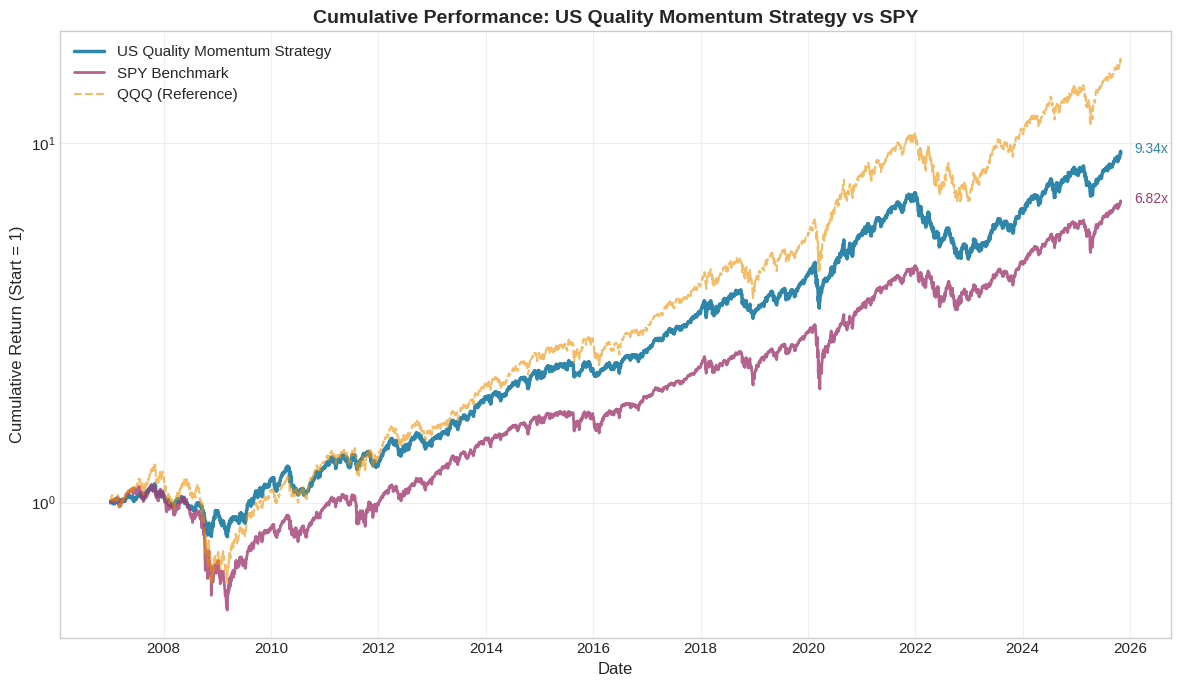


Final Cumulative Returns:
  Strategy (Net): 9.34x (833.72%)
  SPY Benchmark:  6.82x (581.95%)
  Outperformance: 36.92%


In [ ]:
# Calculate cumulative returns
cum_strategy = (1 + rets['strategy']).cumprod()
cum_strategy_net = (1 + rets['strategy_net']).cumprod()
cum_bm = (1 + rets['benchmark']).cumprod()

# Also track QQQ for comparison
cum_qqq = (1 + returns['QQQ']).cumprod()

# Create DataFrame
cum_df = pd.DataFrame({
    'Strategy (Net)': cum_strategy_net,
    'SPY Benchmark': cum_bm,
    'QQQ (Reference)': cum_qqq
})

# Plot
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(cum_df.index, cum_df['Strategy (Net)'], label='US Quality Momentum Strategy',
        linewidth=2.5, color='#2E86AB')
ax.plot(cum_df.index, cum_df['SPY Benchmark'], label='SPY Benchmark',
        linewidth=2, color='#A23B72', alpha=0.8)
ax.plot(cum_df.index, cum_df['QQQ (Reference)'], label='QQQ (Reference)',
        linewidth=1.5, color='#F18F01', alpha=0.6, linestyle='--')

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Cumulative Return (Start = 1)', fontsize=12)
ax.set_title('Cumulative Performance: US Quality Momentum Strategy vs SPY',
             fontsize=14, fontweight='bold')
ax.legend(loc='upper left', fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_yscale('log')

# Annotations
final_strat = cum_df['Strategy (Net)'].iloc[-1]
final_bm = cum_df['SPY Benchmark'].iloc[-1]
ax.annotate(f'{final_strat:.2f}x', xy=(cum_df.index[-1], final_strat),
            xytext=(10, 0), textcoords='offset points', fontsize=10, color='#2E86AB')
ax.annotate(f'{final_bm:.2f}x', xy=(cum_df.index[-1], final_bm),
            xytext=(10, 0), textcoords='offset points', fontsize=10, color='#A23B72')

plt.tight_layout()
plt.savefig('cumulative_performance.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nFinal Cumulative Returns:")
print(f"  Strategy (Net): {final_strat:.2f}x ({(final_strat - 1):.2%})")
print(f"  SPY Benchmark:  {final_bm:.2f}x ({(final_bm - 1):.2%})")
print(f"  Outperformance: {(final_strat/final_bm - 1):.2%}")

## 9. Performance Metrics

In [ ]:
def ann_return(r, freq=TRADING_DAYS):
    total_ret = (1 + r).prod()
    n_periods = len(r)
    return total_ret ** (freq / n_periods) - 1

def ann_vol(r, freq=TRADING_DAYS):
    return r.std() * np.sqrt(freq)

def sharpe_ratio(r, rf, freq=TRADING_DAYS):
    excess = r - rf
    return ann_return(excess, freq) / ann_vol(excess, freq)

def sortino_ratio(r, rf, freq=TRADING_DAYS):
    excess = r - rf
    downside = excess[excess < 0]
    if len(downside) == 0:
        return np.nan
    return ann_return(excess, freq) / (downside.std() * np.sqrt(freq))

def beta_vs_benchmark(r, r_bm, rf):
    excess_r = r - rf
    excess_bm = r_bm - rf
    cov = np.cov(excess_r, excess_bm)[0, 1]
    var_bm = np.var(excess_bm, ddof=1)
    return cov / var_bm

def alpha_jensen(r, r_bm, rf, freq=TRADING_DAYS):
    beta = beta_vs_benchmark(r, r_bm, rf)
    ann_r = ann_return(r, freq)
    ann_bm = ann_return(r_bm, freq)
    ann_rf = rf.mean() * freq
    return ann_r - (ann_rf + beta * (ann_bm - ann_rf))

def information_ratio(r, r_bm, freq=TRADING_DAYS):
    active = r - r_bm
    return ann_return(active, freq) / (active.std() * np.sqrt(freq))

def tracking_error(r, r_bm, freq=TRADING_DAYS):
    return (r - r_bm).std() * np.sqrt(freq)

def max_drawdown(cum_series):
    hwm = cum_series.cummax()
    dd = (hwm - cum_series) / hwm
    return dd.max(), dd

def calmar_ratio(r, cum_series, freq=TRADING_DAYS):
    mdd, _ = max_drawdown(cum_series)
    return ann_return(r, freq) / mdd if mdd > 0 else np.nan

def capture_ratios(r, r_bm, freq='ME'):
    r_m = (1 + r).resample(freq).prod() - 1
    r_bm_m = (1 + r_bm).resample(freq).prod() - 1

    up = r_bm_m > 0
    down = r_bm_m < 0

    up_cap = r_m[up].mean() / r_bm_m[up].mean() if up.any() else np.nan
    down_cap = r_m[down].mean() / r_bm_m[down].mean() if down.any() else np.nan

    return up_cap, down_cap

In [ ]:
# Compute metrics
r_strat = rets['strategy_net']
r_bm = rets['benchmark']

ann_ret_strat = ann_return(r_strat)
ann_ret_bm = ann_return(r_bm)

ann_vol_strat = ann_vol(r_strat)
ann_vol_bm = ann_vol(r_bm)

sharpe_strat = sharpe_ratio(r_strat, rf_daily)
sharpe_bm = sharpe_ratio(r_bm, rf_daily)

sortino_strat = sortino_ratio(r_strat, rf_daily)
sortino_bm = sortino_ratio(r_bm, rf_daily)

beta_strat = beta_vs_benchmark(r_strat, r_bm, rf_daily)
alpha_strat = alpha_jensen(r_strat, r_bm, rf_daily)

ir_strat = information_ratio(r_strat, r_bm)
te_strat = tracking_error(r_strat, r_bm)

dd_strat, dd_series_strat = max_drawdown(cum_strategy_net)
dd_bm, dd_series_bm = max_drawdown(cum_bm)

calmar_strat = calmar_ratio(r_strat, cum_strategy_net)
calmar_bm = calmar_ratio(r_bm, cum_bm)

up_cap, down_cap = capture_ratios(r_strat, r_bm)

In [ ]:
# Create summary table
summary = pd.DataFrame({
    'Strategy': [
        ann_ret_strat, ann_vol_strat, sharpe_strat, sortino_strat,
        beta_strat, alpha_strat, ir_strat, te_strat,
        calmar_strat, up_cap, down_cap, dd_strat,
        r_strat.skew(), r_strat.kurtosis()
    ],
    'Benchmark': [
        ann_ret_bm, ann_vol_bm, sharpe_bm, sortino_bm,
        1.0, 0.0, 0.0, 0.0,
        calmar_bm, 1.0, 1.0, dd_bm,
        r_bm.skew(), r_bm.kurtosis()
    ]
}, index=[
    'Annualized Return', 'Annualized Volatility', 'Sharpe Ratio', 'Sortino Ratio',
    'Beta vs Benchmark', "Jensen's Alpha", 'Information Ratio', 'Tracking Error',
    'Calmar Ratio', 'Up-Market Capture', 'Down-Market Capture', 'Maximum Drawdown',
    'Skewness', 'Excess Kurtosis'
])

# Format
summary_formatted = summary.copy().astype('object')

pct_rows = ['Annualized Return', 'Annualized Volatility', "Jensen's Alpha",
            'Tracking Error', 'Maximum Drawdown']
for row in pct_rows:
    summary_formatted.loc[row] = summary_formatted.loc[row].apply(lambda x: f"{x:.2%}")

decimal_rows = ['Sharpe Ratio', 'Sortino Ratio', 'Beta vs Benchmark', 'Information Ratio',
                'Calmar Ratio', 'Up-Market Capture', 'Down-Market Capture', 'Skewness', 'Excess Kurtosis']
for row in decimal_rows:
    summary_formatted.loc[row] = summary_formatted.loc[row].apply(lambda x: f"{x:.2f}")

print("="*60)
print("PERFORMANCE SUMMARY")
print("US Quality Momentum Strategy vs SPY Benchmark")
print("="*60)
display(summary_formatted)

PERFORMANCE SUMMARY
US Quality Momentum Strategy vs SPY Benchmark


,Strategy,Benchmark
Annualized Return,12.62%,10.75%
Annualized Volatility,15.15%,19.82%
Sharpe Ratio,0.73,0.46
Sortino Ratio,0.95,0.57
Beta vs Benchmark,0.62,1.00
Jensen's Alpha,5.42%,0.00%
Information Ratio,0.02,0.00
Tracking Error,11.68%,0.00%
Calmar Ratio,0.37,0.19
Up-Market Capture,0.92,1.00


## 10. Calendar Year Returns

In [ ]:
# Calendar year returns
yearly_perf = pd.DataFrame({
    'Strategy': (1 + r_strat).resample('YE').prod() - 1,
    'Benchmark': (1 + r_bm).resample('YE').prod() - 1
})
yearly_perf.index = yearly_perf.index.year
yearly_perf['Excess'] = yearly_perf['Strategy'] - yearly_perf['Benchmark']

yearly_perf_fmt = yearly_perf.map(lambda x: f"{x:.2%}")

print("="*60)
print("CALENDAR YEAR RETURNS")
print("="*60)
display(yearly_perf_fmt)

outperf_years = (yearly_perf['Excess'] > 0).sum()
total_years = len(yearly_perf)
print(f"\nYears of outperformance: {outperf_years}/{total_years} ({outperf_years/total_years:.1%})")

CALENDAR YEAR RETURNS


,Strategy,Benchmark,Excess
Date,,,
2007,4.93%,5.33%,-0.40%
2008,-10.08%,-36.79%,26.71%
2009,21.41%,26.35%,-4.94%
2010,8.68%,15.06%,-6.38%
2011,1.88%,1.89%,-0.01%
2012,15.21%,15.99%,-0.78%
2013,34.94%,32.31%,2.63%
2014,16.14%,13.46%,2.68%
2015,0.88%,1.23%,-0.35%



Years of outperformance: 9/19 (47.4%)


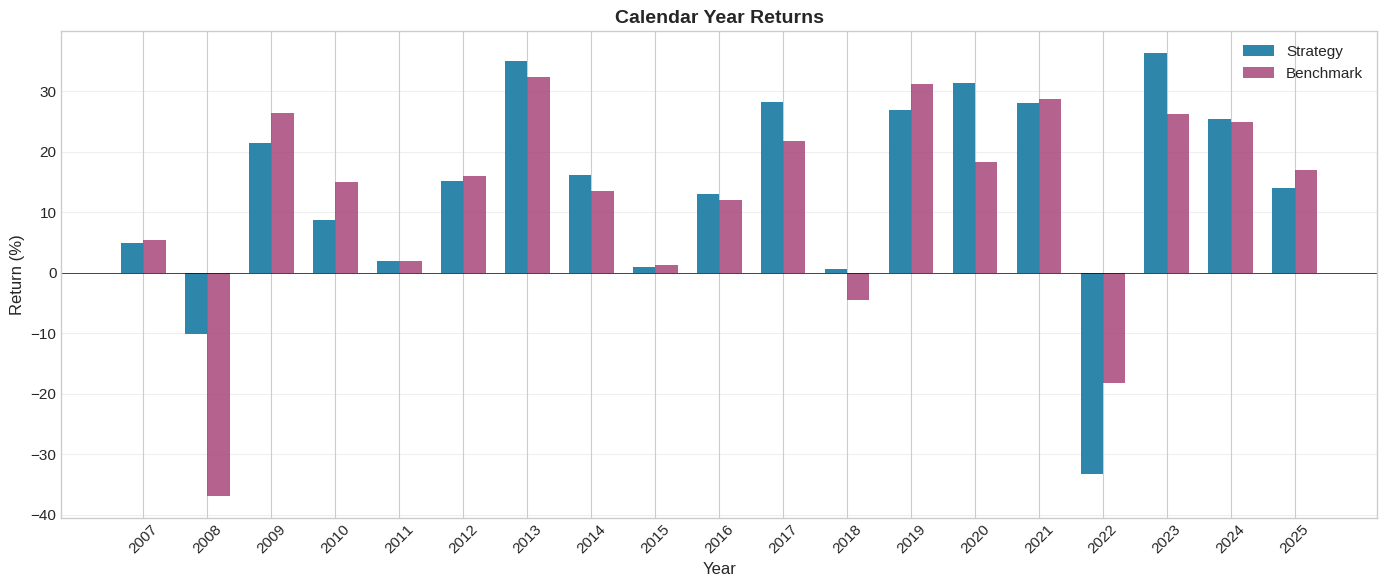

In [ ]:
# Plot calendar year returns
fig, ax = plt.subplots(figsize=(14, 6))

x = np.arange(len(yearly_perf))
width = 0.35

ax.bar(x - width/2, yearly_perf['Strategy'] * 100, width, label='Strategy', color='#2E86AB')
ax.bar(x + width/2, yearly_perf['Benchmark'] * 100, width, label='Benchmark', color='#A23B72', alpha=0.8)

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Return (%)', fontsize=12)
ax.set_title('Calendar Year Returns', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(yearly_perf.index, rotation=45)
ax.legend()
ax.axhline(0, color='black', linewidth=0.5)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('calendar_year_returns.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Drawdown Analysis

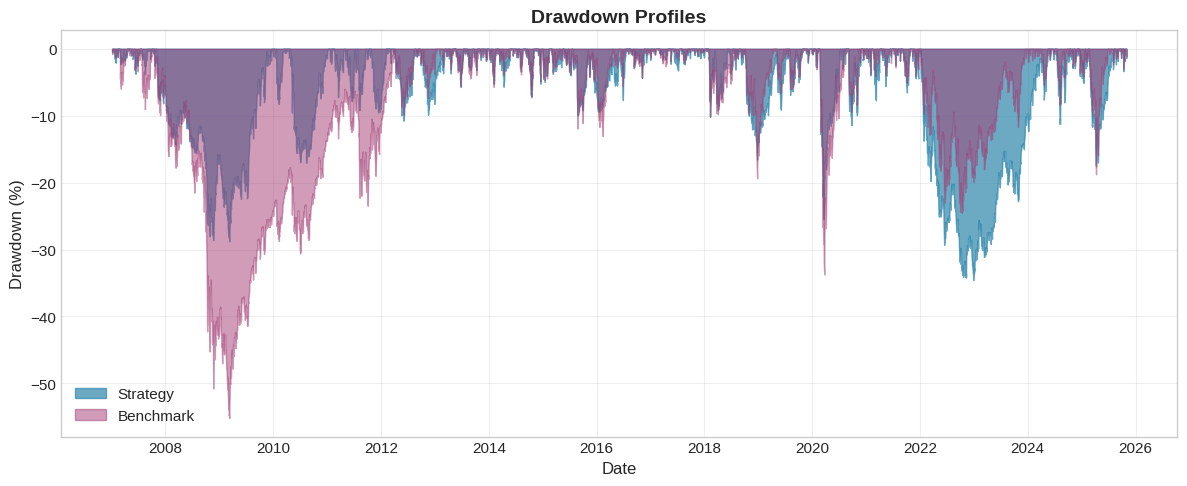

Max Drawdown - Strategy: 34.57%
Max Drawdown - Benchmark: 55.19%


In [ ]:
# Plot drawdowns
fig, ax = plt.subplots(figsize=(12, 5))

ax.fill_between(dd_series_strat.index, 0, -dd_series_strat * 100,
                label='Strategy', alpha=0.7, color='#2E86AB')
ax.fill_between(dd_series_bm.index, 0, -dd_series_bm * 100,
                label='Benchmark', alpha=0.5, color='#A23B72')

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Drawdown (%)', fontsize=12)
ax.set_title('Drawdown Profiles', fontsize=14, fontweight='bold')
ax.legend(loc='lower left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('drawdown_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Max Drawdown - Strategy: {dd_strat:.2%}")
print(f"Max Drawdown - Benchmark: {dd_bm:.2%}")

## 12. Rolling Analysis

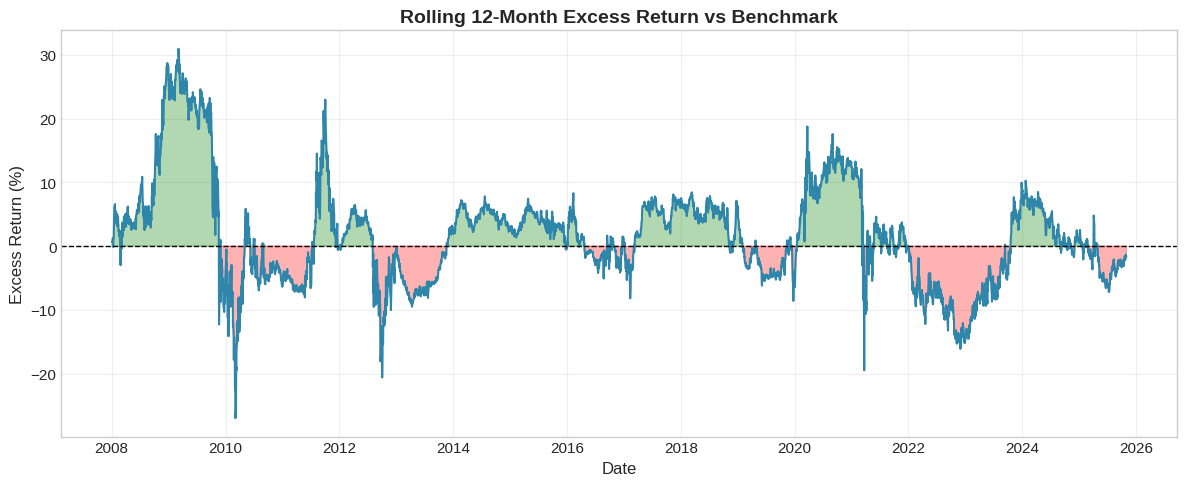

In [ ]:
# Rolling 12-month excess return
rolling_window = 252

rolling_strat = (1 + r_strat).rolling(rolling_window).apply(np.prod, raw=True) - 1
rolling_bm = (1 + r_bm).rolling(rolling_window).apply(np.prod, raw=True) - 1
rolling_excess = rolling_strat - rolling_bm

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(rolling_excess.index, rolling_excess * 100, color='#2E86AB', linewidth=1.5)
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.fill_between(rolling_excess.index, 0, rolling_excess * 100,
                where=(rolling_excess >= 0), alpha=0.3, color='green')
ax.fill_between(rolling_excess.index, 0, rolling_excess * 100,
                where=(rolling_excess < 0), alpha=0.3, color='red')

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Excess Return (%)', fontsize=12)
ax.set_title('Rolling 12-Month Excess Return vs Benchmark', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('rolling_excess_return.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Regime Analysis

In [ ]:
# Performance by regime
risk_on_mask = signal == 1
risk_off_mask = signal == 0

regime_stats = pd.DataFrame({
    'Risk-On': [
        ann_return(r_strat[risk_on_mask]),
        ann_vol(r_strat[risk_on_mask]),
        ann_return(r_bm[risk_on_mask]),
        ann_vol(r_bm[risk_on_mask])
    ],
    'Risk-Off': [
        ann_return(r_strat[risk_off_mask]) if risk_off_mask.sum() > 0 else np.nan,
        ann_vol(r_strat[risk_off_mask]) if risk_off_mask.sum() > 0 else np.nan,
        ann_return(r_bm[risk_off_mask]) if risk_off_mask.sum() > 0 else np.nan,
        ann_vol(r_bm[risk_off_mask]) if risk_off_mask.sum() > 0 else np.nan
    ]
}, index=['Strategy Return', 'Strategy Vol', 'Benchmark Return', 'Benchmark Vol'])

regime_stats_fmt = regime_stats.map(lambda x: f"{x:.2%}" if pd.notnull(x) else "-")

print("="*60)
print("REGIME ANALYSIS")
print("="*60)
display(regime_stats_fmt)

REGIME ANALYSIS


,Risk-On,Risk-Off
Strategy Return,14.83%,6.50%
Strategy Vol,14.99%,15.59%
Benchmark Return,11.64%,8.24%
Benchmark Vol,13.29%,31.88%


## 14. Implementation Details

### Rebalancing
- **Signal Check:** Daily (SPY vs 200-day MA)
- **Rebalancing:** Only when regime changes
- **Execution:** Next day open

### Transaction Costs
- 10 bps per trade (one-way)
- ~50% turnover per regime switch

### Risk Management
- **Trend filter** avoids prolonged bear markets
- **QQQ tilt** captures growth premium
- **TLT allocation** in risk-off provides flight-to-quality

In [ ]:
# Implementation summary
impl_stats = pd.DataFrame({
    'Metric': [
        'Investment Period',
        'Total Trading Days',
        'Regime Switches',
        'Total Transaction Costs',
        'Time in Risk-On',
        'Time in Risk-Off'
    ],
    'Value': [
        f"{rets.index[0].strftime('%Y-%m-%d')} to {rets.index[-1].strftime('%Y-%m-%d')}",
        f"{len(rets):,}",
        f"{num_switches}",
        f"{total_tc:.2%}",
        f"{risk_on_days/len(signal):.1%}",
        f"{risk_off_days/len(signal):.1%}"
    ]
})

print("="*60)
print("IMPLEMENTATION SUMMARY")
print("="*60)
display(impl_stats.set_index('Metric'))

IMPLEMENTATION SUMMARY


,Value
Metric,
Investment Period,2007-01-04 to 2025-10-30
Total Trading Days,"4,737"
Regime Switches,103
Total Transaction Costs,10.30%
Time in Risk-On,74.2%
Time in Risk-Off,25.8%


## 15. Key Takeaways

In [ ]:
print("="*60)
print("KEY PERFORMANCE HIGHLIGHTS")
print("="*60)
print(f"\nAnnualized Return: {ann_ret_strat:.2%} (vs Benchmark: {ann_ret_bm:.2%})")
print(f"Annualized Volatility: {ann_vol_strat:.2%} (vs Benchmark: {ann_vol_bm:.2%})")
print(f"Sharpe Ratio: {sharpe_strat:.2f} (vs Benchmark: {sharpe_bm:.2f})")
print(f"Maximum Drawdown: {dd_strat:.2%} (vs Benchmark: {dd_bm:.2%})")
print(f"\n--- OUTPERFORMANCE ---")
print(f"Excess Return: {(ann_ret_strat - ann_ret_bm):.2%} per year")
print(f"Final Wealth: {final_strat:.2f}x vs {final_bm:.2f}x")
print(f"Outperformance: {(final_strat/final_bm - 1):.1%}")

KEY PERFORMANCE HIGHLIGHTS

Annualized Return: 12.62% (vs Benchmark: 10.75%)
Annualized Volatility: 15.15% (vs Benchmark: 19.82%)
Sharpe Ratio: 0.73 (vs Benchmark: 0.46)
Maximum Drawdown: 34.57% (vs Benchmark: 55.19%)

--- OUTPERFORMANCE ---
Excess Return: 1.87% per year
Final Wealth: 9.34x vs 6.82x
Outperformance: 36.9%


In [ ]:
# Save files
summary_formatted.to_csv('performance_summary.csv')
yearly_perf_fmt.to_csv('calendar_year_returns.csv')
print("Files saved successfully!")

Files saved successfully!
